<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS09Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Load data
import pandas as pd
data = pd.read_csv('iris1.csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
data.info()
data.describe()
data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


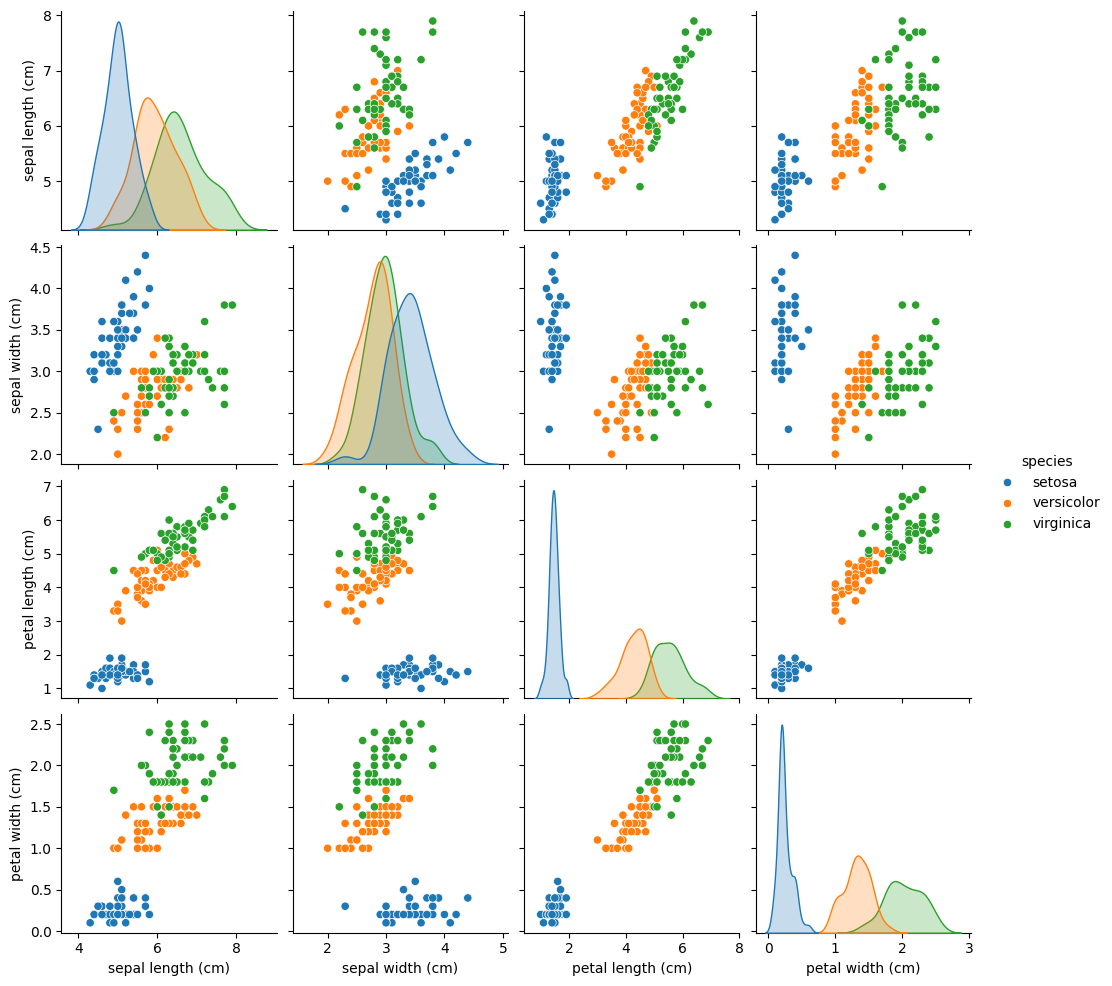

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



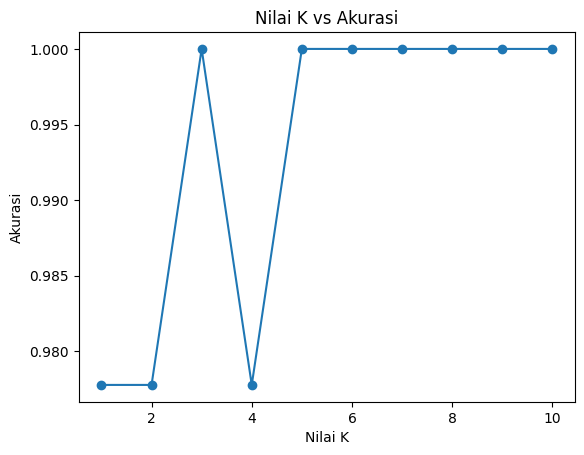

In [ ]:
acc = []
for k in range(1, 11):
   model = KNeighborsClassifier(n_neighbors=k)
   model.fit(X_train, y_train)
   acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


In [1]:
# Load data
import pandas as pd
data = pd.read_csv('properti_multi_kota.csv')
data.head()

data.info()
data.describe()
# Karena dataset ini regresi, kita buat kolom target kategori (kelas harga) untuk keperluan klasifikasi kNN
data['kategori_harga'] = pd.qcut(data['harga'], q=3, labels=['Murah', 'Sedang', 'Mahal'])
data['kategori_harga'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64650 entries, 0 to 64649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sumber              64650 non-null  object 
 1   lokasi              64650 non-null  object 
 2   luas_m2             64650 non-null  float64
 3   luas_bangunan       63046 non-null  float64
 4   jumlah_kamar        64254 non-null  float64
 5   jumlah_kamar_mandi  64242 non-null  float64
 6   usia_bangunan       4789 non-null   float64
 7   harga               64650 non-null  float64
dtypes: float64(6), object(2)
memory usage: 3.9+ MB


,count
kategori_harga,
Murah,21555
Mahal,21550
Sedang,21545


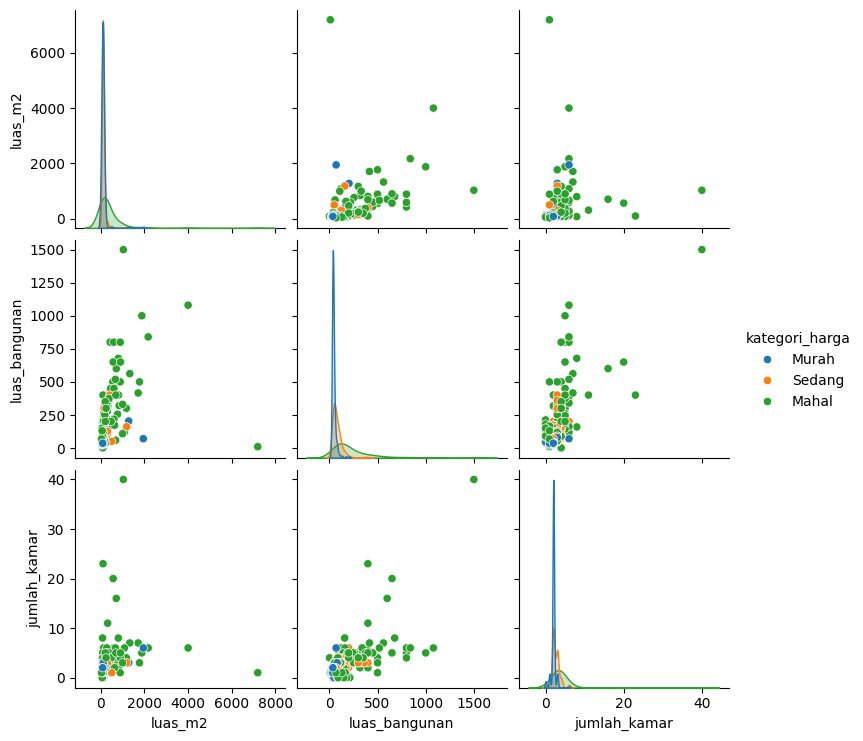

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Memilih beberapa kolom numerik properti untuk pairplot (mengambil sampel 500 baris agar rendering cepat)
cols_to_plot = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'kategori_harga']
sns.pairplot(data[cols_to_plot].dropna().sample(n=min(500, len(data)), random_state=42), hue='kategori_harga')
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Imputasi missing value dengan median
for col in ['luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']:
    data[col] = data[col].fillna(data[col].median())

# Filter outlier ekstrem (hingga persentil ke-95) agar sebaran kNN akurat
data_clean = data[
    (data['luas_m2'] > 0) & (data['luas_m2'] <= data['luas_m2'].quantile(0.95)) &
    (data['luas_bangunan'] > 0) & (data['luas_bangunan'] <= data['luas_bangunan'].quantile(0.95)) &
    (data['jumlah_kamar'] > 0) & (data['jumlah_kamar'] <= 15)
].copy()

# Fitur X dan Target y (kategori_harga)
X = data_clean[['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']]
y = data_clean['kategori_harga']

# Split data (70% train, 30% test) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Akurasi: 0.6810732833237161
Confusion Matrix:
 [[3778  165  963]
 [ 270 4602 1393]
 [1247 1489 3423]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

       Mahal       0.71      0.77      0.74      4906
       Murah       0.74      0.73      0.74      6265
      Sedang       0.59      0.56      0.57      6159

    accuracy                           0.68     17330
   macro avg       0.68      0.69      0.68     17330
weighted avg       0.68      0.68      0.68     17330



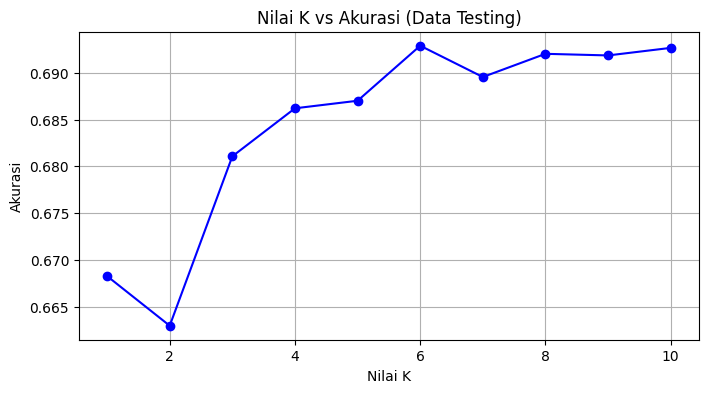

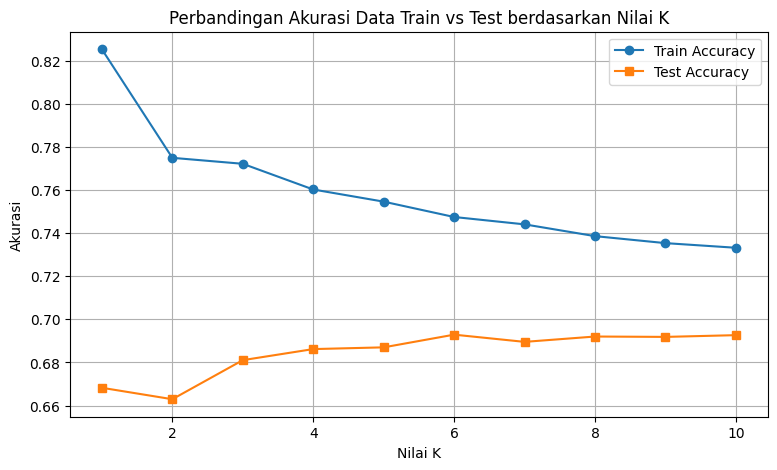

In [5]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

# Evaluasi setiap nilai k dari 1 hingga 10 pada data testing
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), acc, marker='o', color='b')
plt.title('Nilai K vs Akurasi (Data Testing)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.grid(True)
plt.show()

# Perbandingan akurasi Train vs Test untuk setiap nilai k
acc_train = []
acc_test = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc_train.append(model.score(X_train, y_train))
    acc_test.append(model.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(range(1, 11), acc_train, marker='o', label='Train Accuracy')
plt.plot(range(1, 11), acc_test, marker='s', label='Test Accuracy')
plt.title('Perbandingan Akurasi Data Train vs Test berdasarkan Nilai K')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()